# Module 4 — Is temperature risk priced in stock returns?

**Project:** *Pricing the Future*, an empirical extension of my M.Sc. project (University of Bath), *"Empirical analysis of asset pricing models."*

**The question.** Module 3 found that the standard consumption-based model gives climate damages an almost zero risk premium: consumption is too smooth to make anything look risky. That is the equity premium puzzle in a climate setting. But markets price stocks at far higher risk premia than that model predicts. So: **do investors demand compensation for exposure to temperature shocks?**

**The approach** follows Bansal, Kiku & Ochoa (2016), using the standard empirical asset-pricing toolkit:

1. **Temperature shocks:** the part of monthly temperature investors could *not* anticipate.
2. **Temperature betas:** how each of the 49 Fama–French industry portfolios responds to those shocks, controlling for the market, size and value factors.
3. **Fama–MacBeth (1973) regressions:** whether industries with more temperature exposure earn higher (or lower) average returns, i.e. a *price of temperature risk*.

All computation lives in `R/08_temperature_risk.R`; this notebook runs it and explains the results.

In [1]:
# --- Setup -------------------------------------------------------------------
if (basename(getwd()) == "notebooks") setwd("..")
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 120)
source("R/08_temperature_risk.R")

[20:44:43] Shocks built. Persistence of anomaly: US rho = 0.25, global rho = 0.86
[20:44:44] Panel: 49 industries, 1960-01-01 to 2026-09-01
[20:44:45] Fama-MacBeth: running 5 specifications (rolling 60-month betas) ...
[20:44:59] Saved tables 4-5
[20:45:02] Saved figures 8-9

================ STEP 5 / MODULE 4 KEY RESULTS ================
Sample 1960-01-01 to 2026-09-01, 49 industries
Temperature anomaly persistence: US rho = 0.25, global rho = 0.86
Industries with a significant US temperature beta (5%): 4 of 49 (expect ~2 by chance)

Most positive temperature betas:
 industry beta_temp nw_se    t months
     Gold     0.691 0.417 1.66    759
    Autos     0.532 0.247 2.15    801
    Steel     0.313 0.180 1.74    801
    Mines     0.241 0.224 1.08    801
      Fun     0.220 0.207 1.06    801

Most negative temperature betas:
 industry beta_temp nw_se     t months
     Guns    -0.323 0.203 -1.59    759
    Clths    -0.333 0.167 -2.00    801
     Hlth    -0.405 0.266 -1.53    687
    Txtl

## 1. Temperature shocks

Investors know that July is hot, that the climate is warming, and that a hot month tends to follow a hot month. None of that is news, so none of it should move prices. The **shock** is what's left after removing all three:

$$a_t = T_t - \bar T_{m(t)}, \qquad a_t = c + \delta\, t + \rho\, a_{t-1} + \varepsilon_t, \qquad \text{shock}_t = \hat\varepsilon_t$$

where $\bar T_{m(t)}$ is that calendar month's 1951–80 average. We build shocks for the **US** (ERA5 reanalysis, where most of the 49 industries operate) and the **globe** (NASA GISTEMP).

Persistence of monthly temperature anomalies: US rho = 0.25, global rho = 0.86
Std. dev. of shocks: US 0.90°C, global 0.12°C


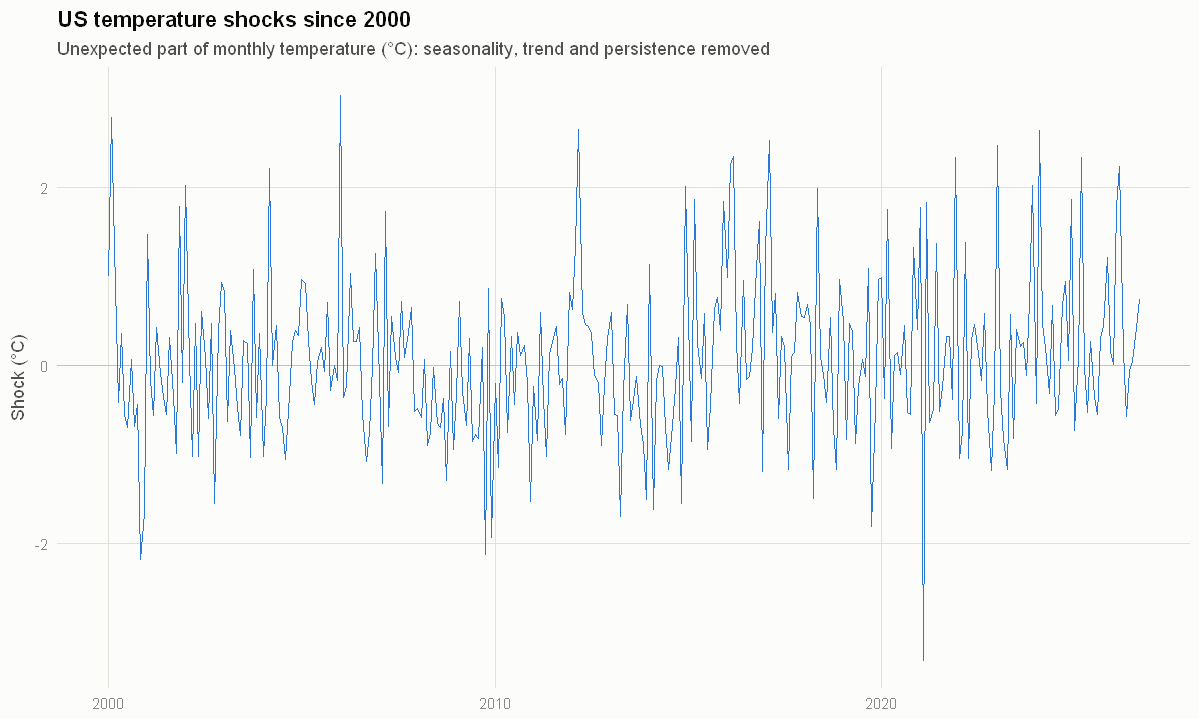

In [2]:
cat(sprintf("Persistence of monthly temperature anomalies: US rho = %.2f, global rho = %.2f\n", rho_us, rho_gl))
cat(sprintf("Std. dev. of shocks: US %.2f°C, global %.2f°C\n",
            sd(shocks$shock_us, na.rm = TRUE), sd(shocks$shock_gl, na.rm = TRUE)))

shocks |>
  filter(date >= as.Date("2000-01-01"), !is.na(shock_us)) |>
  ggplot(aes(date, shock_us)) +
  geom_hline(yintercept = 0, colour = "#c3c2b7") +
  geom_line(colour = COL_MAIN, linewidth = 0.4) +
  labs(title = "US temperature shocks since 2000",
       subtitle = "Unexpected part of monthly temperature (°C): seasonality, trend and persistence removed",
       x = NULL, y = "Shock (°C)") +
  theme_project()

## 2. Temperature betas: who wins and who loses when it's unexpectedly hot?

For each industry $i$, over the full sample:

$$R_{it} - R_{f,t} = \alpha_i + b_i\,\text{MKT}_t + s_i\,\text{SMB}_t + h_i\,\text{HML}_t + \beta^{T}_i\,\text{shock}_t + e_{it}$$

$\beta^T_i$ is the extra monthly return (in %) when US temperature is 1 °C above expectations, *beyond* what the market, size and value factors explain. Standard errors are Newey–West, because monthly returns can be autocorrelated and heteroskedastic.

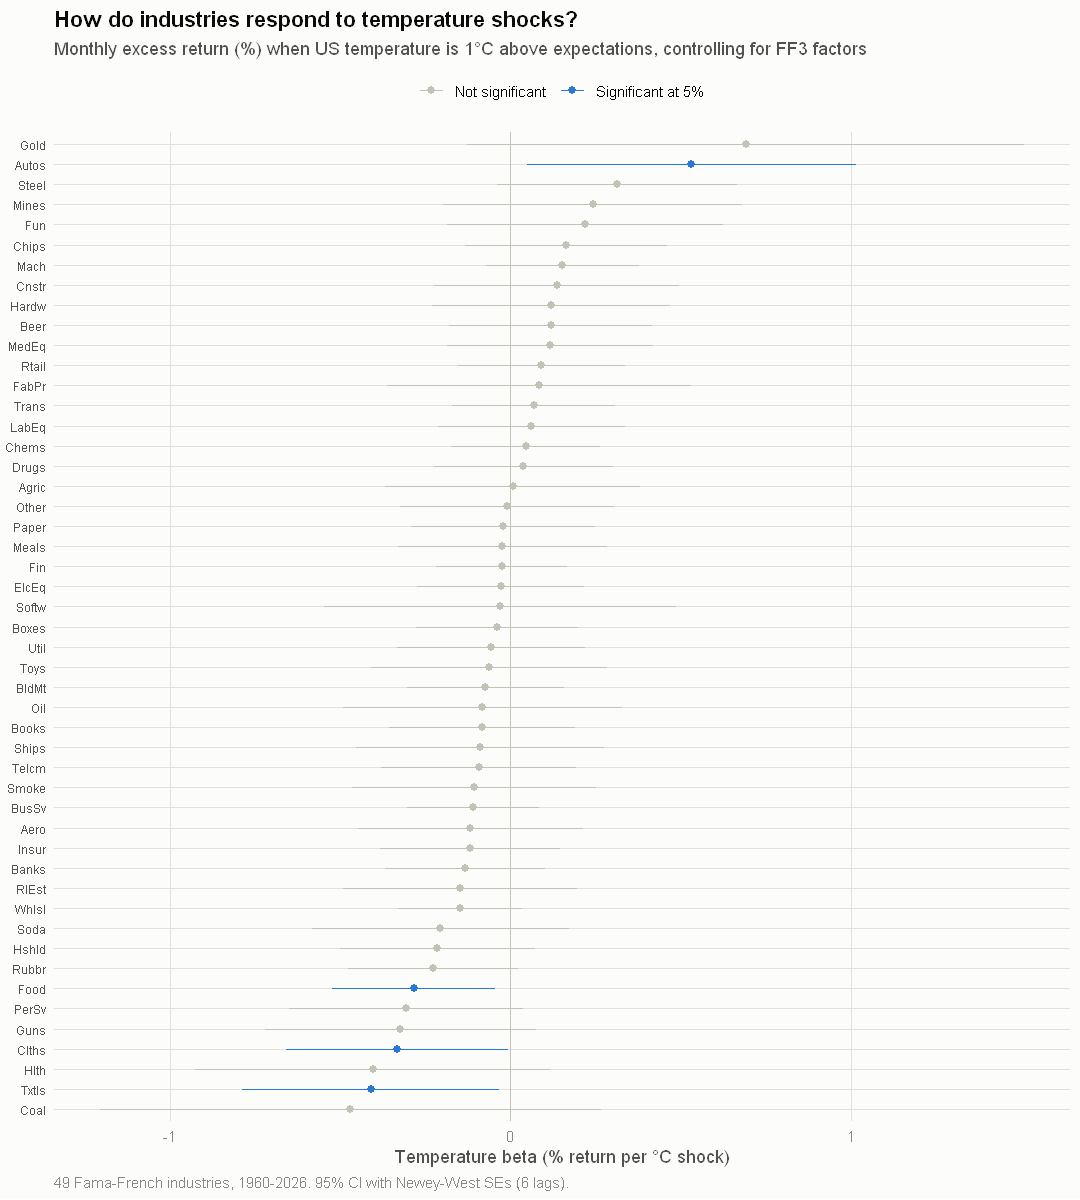

In [3]:
options(repr.plot.width = 9, repr.plot.height = 10)
fig8

In [4]:
cat(sprintf("Significant temperature betas at 5%%: %d of %d industries (about %.0f expected by pure chance)\n\n",
            sum(betas_main$significant), nrow(betas_main), 0.05 * nrow(betas_main)))
cat("Most positive:\n"); print(as.data.frame(head(tab4, 5)), row.names = FALSE)
cat("\nMost negative:\n"); print(as.data.frame(tail(tab4, 5)), row.names = FALSE)

Significant temperature betas at 5%: 4 of 49 industries (about 2 expected by pure chance)

Most positive:
 industry beta_temp nw_se    t months
     Gold     0.691 0.417 1.66    759
    Autos     0.532 0.247 2.15    801
    Steel     0.313 0.180 1.74    801
    Mines     0.241 0.224 1.08    801
      Fun     0.220 0.207 1.06    801

Most negative:
 industry beta_temp nw_se     t months
     Guns    -0.323 0.203 -1.59    759
    Clths    -0.333 0.167 -2.00    801
     Hlth    -0.405 0.266 -1.53    687
    Txtls    -0.410 0.193 -2.13    801
     Coal    -0.470 0.375 -1.25    801


**Reading the betas.** Economic intuition says energy and utilities could benefit from heat (demand for cooling), while agriculture, food, outdoor industries and retail could suffer. If far more industries are significant than the ~2–3 we'd expect by chance, temperature shocks carry real information about cash flows.

## 3. Is temperature exposure *priced*? Fama–MacBeth

A significant beta says temperature moves returns. It does **not** say investors are paid to bear that exposure. That is the question of a risk premium, and the classic test is Fama & MacBeth (1973):

**(a) First pass.** For every industry and month $t$, estimate betas on the previous 60 months only, so there is no look-ahead.

**(b) Second pass.** Every month, regress the 49 industries' returns on their betas:
$$R_{it} - R_{f,t} = \gamma_{0t} + \lambda_{\text{MKT},t}\,b_{it} + \lambda_{\text{SMB},t}\,s_{it} + \lambda_{\text{HML},t}\,h_{it} + \lambda_{T,t}\,\beta^{T}_{it} + u_{it}$$

**(c)** The price of risk is the average $\bar\lambda_T$. Its t-statistic uses Newey–West errors on the $\lambda_{T,t}$ series.

**Interpretation.** $\bar\lambda_T > 0$: investors demand extra return to hold industries that do *well* when it's hot, so hot surprises are "good states". $\bar\lambda_T < 0$: industries that do well in heat are *hedges* investors pay up for, so heat is a "bad state". Bansal, Kiku & Ochoa argue for the latter.

In [5]:
fm_temp |>
  transmute(specification = spec, lambda = round(lambda, 3), `NW t-stat` = round(t, 2), months,
            `premium per 1-sd beta (%/yr)` = round(premium_1sd_annual, 2))

specification,lambda,NW t-stat,months,premium per 1-sd beta (%/yr)
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
FF3 + US temp (main),0.035,0.56,741,0.27
FF3 + global temp,0.007,0.76,741,0.40
FF5 + US temp,0.068,1.08,699,0.54
"FF3 + US temp, post-1990",0.125,1.40,381,1.10
"FF3 + US temp, full-sample betas",0.041,0.19,741,0.11


In [6]:
# All prices of risk in the main specification (do the FF factors earn their usual premia?)
fm_table |> filter(spec == "FF3 + US temp (main)") |>
  transmute(term, lambda = round(lambda, 3), `NW t-stat` = round(t, 2))

term,lambda,NW t-stat
<chr>,<dbl>,<dbl>
const,0.549,3.11
mkt_rf,0.028,0.13
smb,0.122,1.02
hml,0.276,2.03
shock_us,0.035,0.56


**Economic size.** $\bar\lambda_T$ is per unit of beta. Multiplying by the cross-sectional standard deviation of temperature betas, and by 12, gives the extra annual return on an industry one standard deviation more exposed to temperature than average: the *premium per 1-sd beta* column.

**Why rolling betas understate the premium.** Betas estimated on 60 months are noisy, and noise in a regressor biases its coefficient toward zero (errors-in-variables). The *full-sample betas* row uses one beta per industry, estimated on all the data: less noisy, but it uses future information. The truth likely lies between the two. (In a simulation with a known premium of 0.30, rolling betas gave 0.24 and full-sample betas 0.32.)

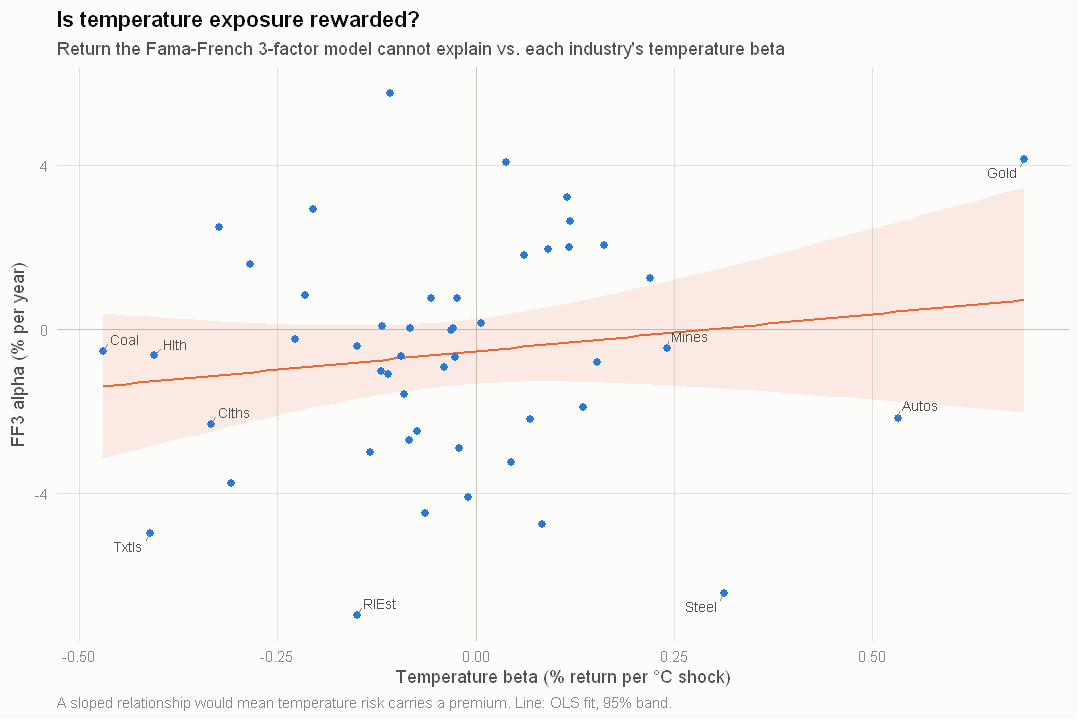

In [7]:
options(repr.plot.width = 9, repr.plot.height = 6)
fig9

## 4. Takeaways and link to Module 3

**1. Monthly temperature shocks carry little information for industry returns.** Only **4 of 49** industries have a temperature beta significant at 5%, against about 2 expected by chance. The few that respond are economically sensible: **clothing** (t = −2.00) and **textiles** (t = −2.13) lose in unexpectedly warm months, consistent with weaker seasonal apparel demand, while **autos** gain (t = 2.15). Point estimates for gold, steel and mining are positive, and for coal and healthcare negative, but none is significant.

**2. Temperature risk is not priced in the cross-section.** The Fama–MacBeth price of temperature risk is small and insignificant in every specification: FF3 (t = 0.56), FF5 (t = 1.08), global shocks (t = 0.76), post-1990 (t = 1.40) and full-sample betas (t = 0.19). An industry one standard deviation more exposed to temperature earns an extra **0.1–1.1% a year**, statistically indistinguishable from zero.

**3. The test itself behaves normally.** HML earns a significant premium (t = 2.03), and the market beta is not priced across industry portfolios, with a large intercept (t = 3.11). That is the familiar Fama–MacBeth pattern with industry portfolios, so the null result for temperature is not a symptom of a broken test.

**4. Link to Module 3: markets and the consumption model agree, at this frequency.** The Ramsey SDF implied a climate risk premium of ≈ 0.04 pp a year. Markets, at least for monthly US weather shocks, also show no significant premium. So **we find no evidence that SDF-based discounting understates how much markets care about short-run temperature risk.**

**5. Why this need not contradict the literature.** Bansal, Kiku & Ochoa (2016) find a significant *negative* premium using **long-run, low-frequency** temperature risk. Long-lived assets should respond to persistent shifts in climate, not to monthly weather noise; US monthly anomalies here are only weakly persistent (ρ = 0.25). Global anomalies are far more persistent (ρ = 0.86), but monthly shocks to them still carry no premium. A natural extension is to build shocks to multi-year moving averages of temperature, or to use climate-news indices (Engle et al. 2020).

**Caveats.** Industry portfolios are a coarse cross-section; firm-level or regional exposures may show stronger effects. Rolling 60-month betas bias λ toward zero (errors-in-variables), but the full-sample-beta specification is also insignificant, so the null does not hinge on that choice.